# 딥러닝 퍼셉트론 요약정리

## 1. 퍼셉트론

### 1-1. 인공신경망과 퍼셉트론

> **핵심** 퍼셉트론은 입력에 가중치를 곱해 더한 값이 기준을 넘는지에 따라 0 또는 1을 내는  단순한 신경망임

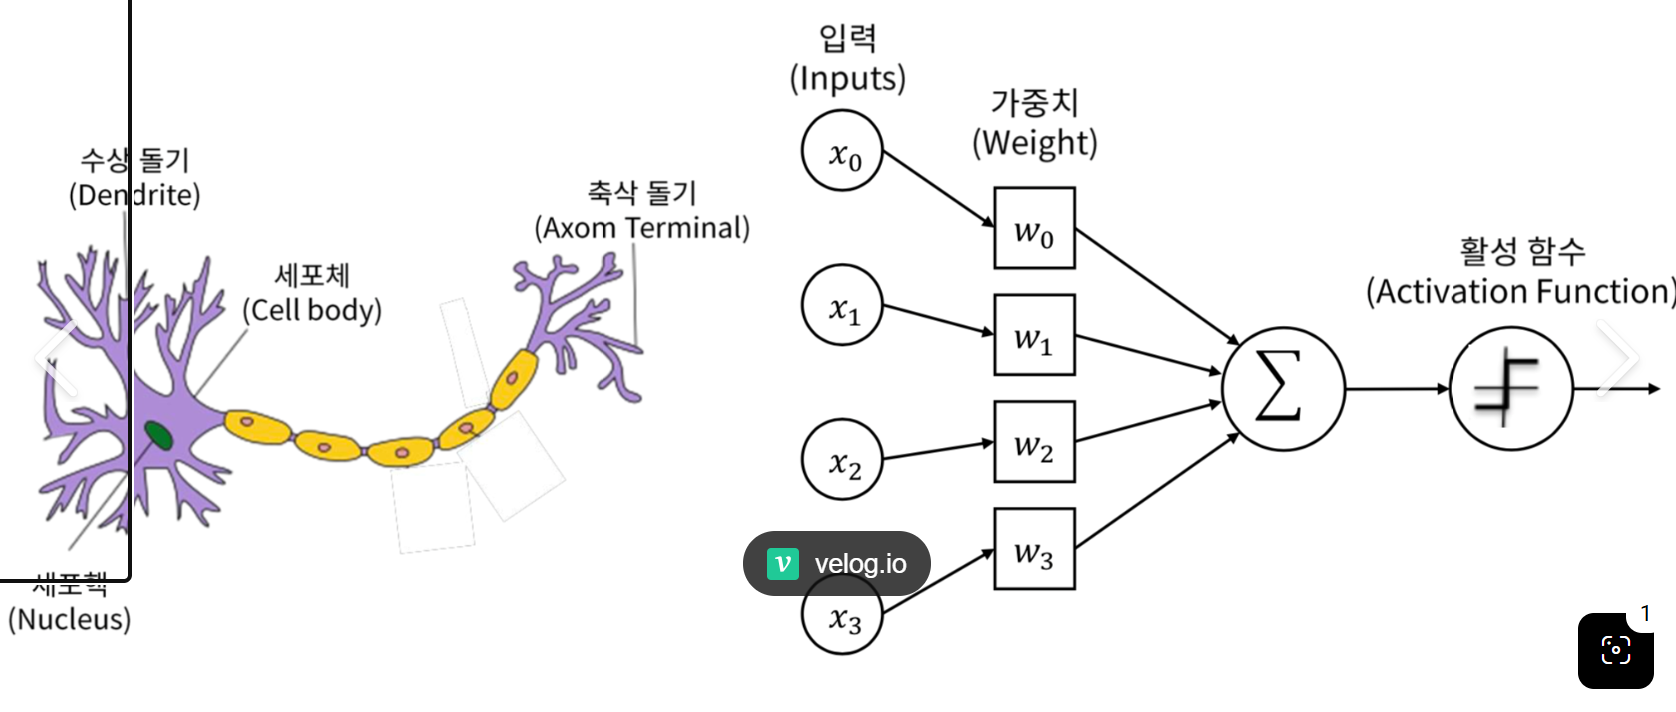

인공신경망은 뇌의 뉴런이 신호를 주고받는 방식을 흉내 낸 모델임. 실제 뉴런은 여러 신호를 받아 모은 뒤, 그 크기가 일정 수준을 넘을 때만 다음 뉴런으로 신호를 넘기는데, 인공신경망은 이 과정을 "입력 × 가중치 + 편향 → 활성화 함수 → 출력"이라는 계산으로 옮겨 놓은 것

| 구분 | 생물학적 신경망 | 인공신경망 | 설명 |
| --- | --- | --- | --- |
| 전체 구조 | 뇌의 신경망 | 인공신경망  | 신경 세포끼리 연결되어 정보를 처리하는 구조를 모방함 |
| 기본 단위 | 뉴런 | 퍼셉트론 | 신호를 받아 처리하고 내보내는 하나의 단위 |
| 신호 입력 | 가지돌기 | 입력값 (x) + 가중치 (w), 편향 (b) | 외부 신호를 받아들임 |
| 신호 판단 | 모인 신호가 일정 크기 이상인지 | 활성화 함수 (임계값 기준) | 기준 미달이면 0에 가깝게, 통과하면 유의미한 값으로 내보냄 |
| 신호 출력 | 축삭돌기 | 출력값 (output) | 다음으로 신호를 전달함 |

퍼셉트론은 이런 인공신경망의 초기 형태이자 딥러닝의 출발점이 된 선형 이진 분류기임. 입력값과 가중치를 곱해 모두 더하고, 그 합이 임계값 θ보다 크면 1, 작으면 0을 출력함. 여기서 말하는 **학습**이란 원하는 출력이 나올 때까지 가중치를 조금씩 맞춰 가는 과정을 뜻함.

**주요 용어**
- **가중치(w)**: 각 입력이 결과에 얼마나 영향을 주는지를 나타내는 값. 클수록 그 입력이 중요하다는 뜻임
- **활성화 함수**: 가중합을 받아 최종 출력을 결정하는 함수. 퍼셉트론은 계단 함수를 썼고, 이후 미분 문제와 기울기 소실 문제를 해결하기 위해 Sigmoid, Tanh, ReLU, Leaky ReLU 등이 등장함
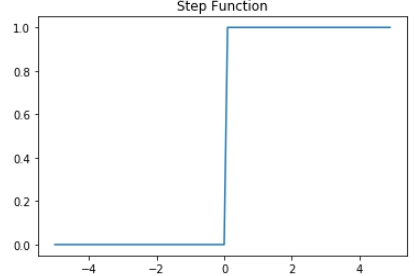
- **임계값(θ)**: 계단 함수에서는 가중합이 임계값을 넘으면 1, 넘지 못하면 0을 출력
- **편향(b)**: 임계값을 식의 좌변으로 옮겨 −θ를 b로 바꿔 쓴 것. 결국 임계값과 같은 역할이며, 표현 방식만 다를 뿐
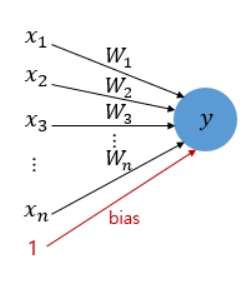
$$
\sum w_i x_i + b \ge 0 \;\Rightarrow\; y = 1, \qquad \sum w_i x_i + b < 0 \;\Rightarrow\; y = 0
$$

---

### 1-2. 단층 퍼셉트론

> **핵심** 단층 퍼셉트론은 직선 하나로 나눌 수 있는 문제만 풀 수 있어서 XOR을 구현하지 못함

단층 퍼셉트론은 입력층과 출력층만으로 이루어진 구조로, 값을 보내고 받아서 출력하는 두 단계가 전부임.

이 구조로 논리 게이트를 만들어 보면 한계가 드러남. 논리 게이트는 여러 입력을 받아 하나의 출력을 내는 디지털 회로의 기본 단위인데,

- **AND**(둘 다 1일 때만 1), **OR**(둘 다 0일 때만 0), **NAND**(둘 다 1일 때만 0)는 w1, w2, b 값만 적절히 정하면 쉽게 구현됨. 예를 들어 AND는 `0.5, 0.5, -0.7` 같은 조합으로 만들 수 있고, NAND는 AND의 부호를 뒤집으면 됨
- 반면 **XOR**(두 입력이 다를 때만 1)은 어떤 조합을 넣어도 4개 경우 중 3개까지만 맞고 끝까지 구현x

이유는 퍼셉트론이 입력과 가중치의 선형 결합, 즉 **직선 하나로 영역을 나누는 구조**이기 때문임. AND는 직선 하나로 0과 1을 가를 수 있지만, XOR은 곡선이나 비선형 경계가 있어야만 나눌 수 있음. 이 한계를 넘기 위해 퍼셉트론을 여러 층으로 쌓는 방식 등장!

---

### 1-3. 다층 퍼셉트론 

> **핵심** 은닉층을 추가하고, 그 은닉층에 비선형 활성화 함수를 적용해야 XOR 같은 비선형 문제를 풀 수 있음

XOR은 이미 만들 수 있는 게이트들을 조합하면 해결됨. 은닉층의 뉴런 두 개가 각각 NAND와 OR을 계산하고, 출력층에서 두 결과를 AND로 묶으면 XOR이 됨. 뉴런 2개짜리 은닉층 하나면 충분함.

여기서 주의할 점은 **층을 쌓는 것 자체가 답은 아니라는 것**임. 활성화 함수 없이 선형 계산만 반복하면 아래처럼 결국 하나의 선형식으로 합쳐져서, 층을 아무리 늘려도 결정 경계는 여전히 직선임.

$$
W_2(W_1x+b_1)+b_2 = Wx+b
$$

MLP가 XOR을 풀 수 있는 진짜 이유는 은닉층에서 비선형 활성화 함수를 거쳐 **새로운 특징을 만들고**, 다음 층이 그 특징을 다시 조합할 수 있기 때문임. 단층 퍼셉트론도 계단 함수를 쓰긴 하지만 한 번 계산하고 끝나므로 경계가 직선에 머무는 반면, 다층 구조는 중간 결과를 재조합할 수 있다는 점이 차이임.

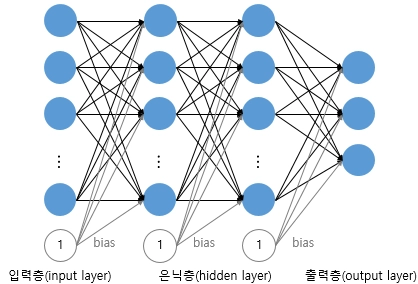

이렇게 입력층, 하나 이상의 은닉층, 출력층으로 구성된 것이 MLP이고, 문제가 복잡할수록 은닉층을 더 많이 쌓을 수 있음. 은닉층이 2개 이상인 신경망을 **심층 신경망** 이라 부르며, 이 심층 신경망이 스스로 가중치를 찾도록 학습시키는 것이 **딥러닝**인거다.

---

## 2. 딥러닝 모델의 학습 과정

### 2-1. 순전파와 역전파

> **핵심** 예측하고, 틀린 정도를 재고, 그 책임을 거꾸로 추적해 가중치를 고치는 과정을 반복함. 이때 책임을 계산하는 도구가 연쇄법칙임

딥러닝의 학습은 아래 순서를 계속 반복하는 구조

1. **순전파**: 입력을 넣어 예측값을 구함 (문제 풀기)
2. **오차 계산**: 예측값과 정답을 비교함 (채점)
3. **역전파**: ***출력층에서 입력층 방향***으로 오차를 되돌려 보냄 (오답노트)
4. **가중치 업데이트**: 계산 결과를 바탕으로 가중치를 수정함 (실력 향상)

반복할수록 오차는 0에 가까워짐.

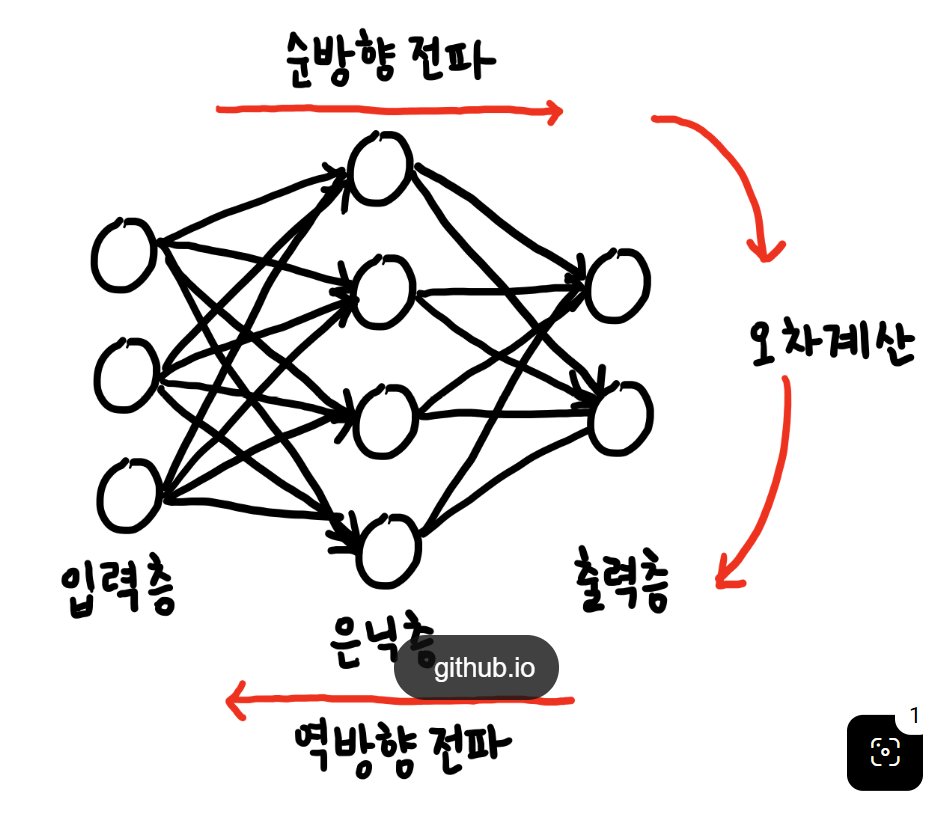

**연쇄법칙**
역전파가 가능한 건 연쇄법칙을 통해. 연쇄법칙은 합성함수의 미분을 각 함수 미분의 곱으로 나타낼 수 있다는 법칙.

$$
\frac{\partial L}{\partial w_1}=\frac{\partial L}{\partial a_n}\times\cdots\times\frac{\partial a_1}{\partial w_1}
$$

**기울기 소실**
그런데 은닉층이 많고 각 층의 미분값이 1보다 작다면, 이걸 계속 곱하는 과정에서 값이 0에 가까워짐. 시그모이드의 미분 최댓값이 정확히 0.25라서, 시그모이드를 여러 층 쓰면 이 현상이 쉽게 발생함. 기울기가 0에 가까워지면 앞쪽 층의 가중치는 거의 바뀌지 않고 학습이 제대로 되지 않음. 이 문제가 뒤에서 ReLU가 등장하는 이유



---

### 2-2. 손실 함수

> **핵심** 회귀는 MSE, 이진 분류는 BCE, 다중 분류는 CEE를 사용!

먼저 비슷한 용어를 구분필요: **목적함수**는 최적화하려는 대상 전체, **손실함수**는 데이터 하나에 대한 오차, **비용함수**는 전체 데이터에 대한 평균 오차를 말함. 손실함수와 비용함수는 최소화가 목표라는 점만 기억하면 됨.

손실 함수는 정답과 예측값의 차이를 계산해 모델이 얼마나 틀렸는지를 숫자로 보여주는 함수이고, 문제 유형에 따라 다른 것을 씀.

**MSE (평균 제곱 오차)**
예측값과 실제값 차이를 제곱해 평균 낸 값. 집값 예측처럼 연속적인 값을 맞히는 회귀 문제에 적합

**BCE (이진 크로스 엔트로피)**
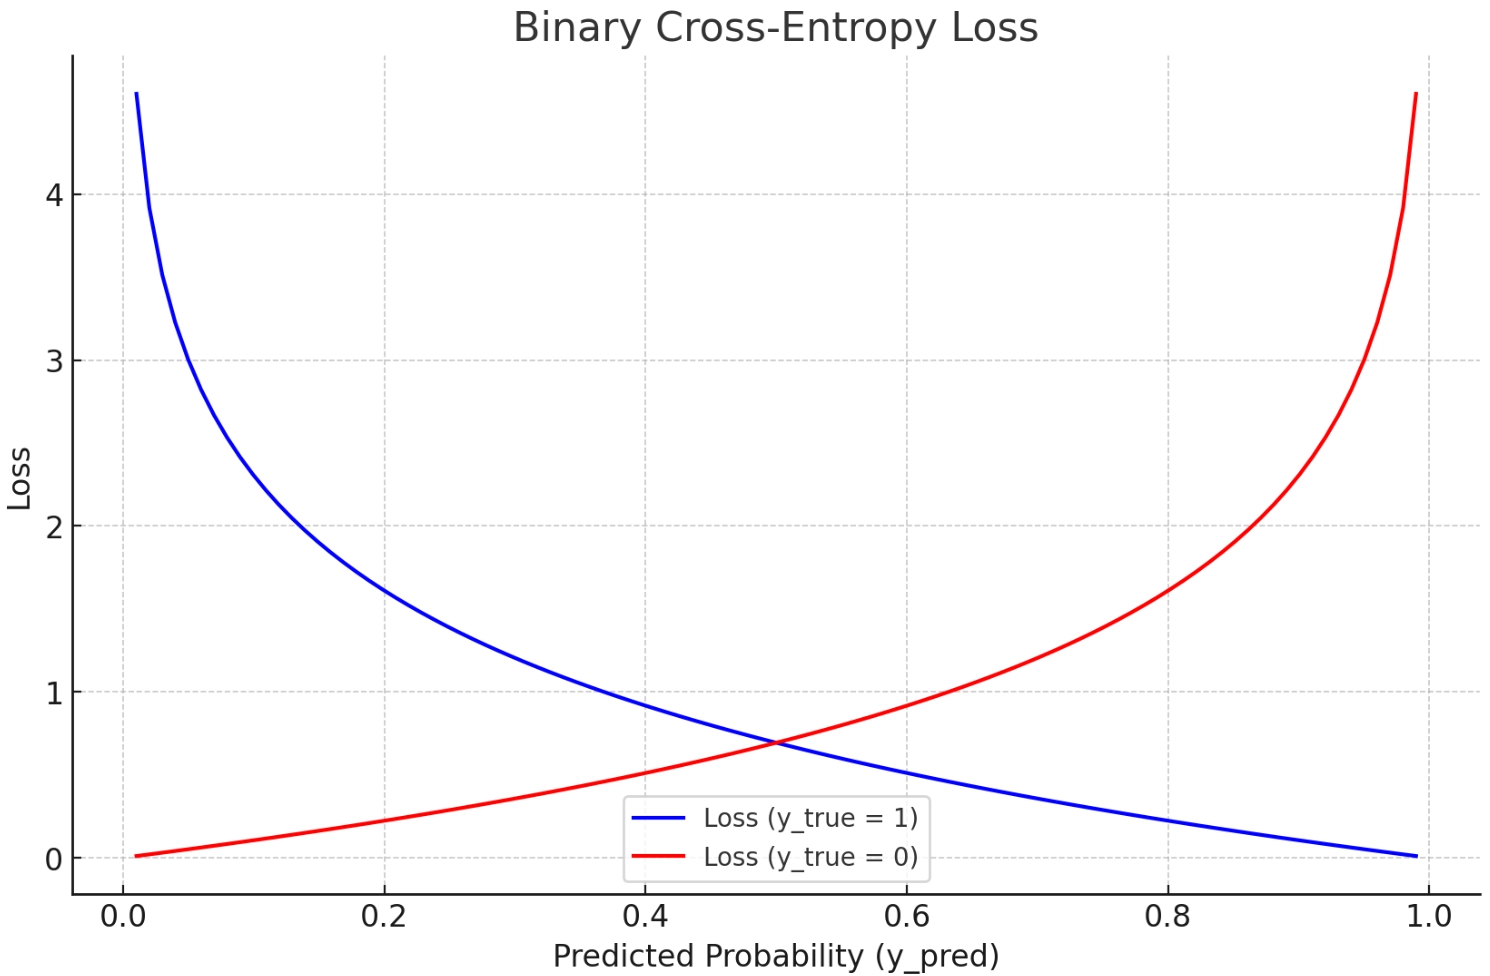
이진 분류에 쓰는 손실 함수로, **정답에 부여한 확률에 −log를 씌운 것**. 정답이 1이면 예측 확률 p가, 정답이 0이면 1−p가 높아야 잘 맞힌 것이므로 정답 쪽 확률이 높을수록 손실이 작아짐. 그래서 BCE는 MSE와 달리 **얼마나 확신하고 예측했는지**까지 손실에 반영. 이름에 엔트로피가 붙은 것도 이렇게 불확실성을 함께 따지기 때문.

$$
L = -\big(y\log\hat{y} + (1-y)\log(1-\hat{y})\big)
$$

**CEE (크로스 엔트로피 오차)**
BCE와 거의 같은 형태지만 다중 클래스 분류에 사용함. 원-핫 인코딩된 정답과 예측 확률이 얼마나 일치하는지를 평가

요약: 
| 손실 함수 | 사용 상황 | 예시 |
| --- | --- | --- |
| MSE | 회귀 문제 | 주택 가격 예측, 온도 예측, 주식 가격 예측 |
| BCE | 이진 분류 문제 | 이메일 스팸 필터링(스팸/정상), 질병 진단(양성/음성) |
| CEE | 다중 클래스 분류 문제 | 손글씨 숫자 인식(MNIST), 이미지 분류(CIFAR-10) |

---

### 2-3. 활성화 함수

> **핵심** 활성화 함수는 비선형성을 주고 미분이 가능해야 함. 은닉층은 ReLU, 출력층은 문제에 따라 Sigmoid나 Softmax를 씀

신경망의 각 층은 wx+b를 계산한 뒤 활성화 함수를 거쳐 출력을 내보냄. 활성화 함수가 필요한 이유는 두 가지

- **비선형성**: 활성화 함수가 없으면 층을 쌓아도 선형 계산의 반복이라 XOR 같은 문제를 풀 수 없음
- **미분 가능성**: 역전파는 미분값을 곱해 나가는 과정이므로, 활성화 함수가 미분되지 않으면 학습 자체가 불가능함

이 두 조건을 만족시키는 과정에서 활성화 함수는 계단 함수 → 시그모이드 → ReLU 순으로 발전해 옴. 단층 퍼셉트론은 계단 함수로 0/1만 출력하고 선형 문제만 풀지만, 다층 퍼셉트론은 Sigmoid, ReLU 등을 써서 연속적인 값을 출력하고 비선형 문제까지 학습할 수 있음.

**계단 함수**

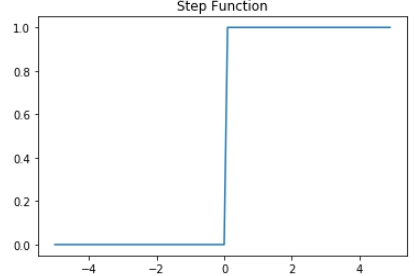
가중합이 기준 이상이면 1, 아니면 0을 출력함. 단층 퍼셉트론에서 쓰였지만, 미분값이 0이라 역전파가 불가능해서 다층 구조에서는 쓰지 않음.
가중치는 각 입력 신호가 결과에 미치는 영향력을 제어!!

**시그모이드**
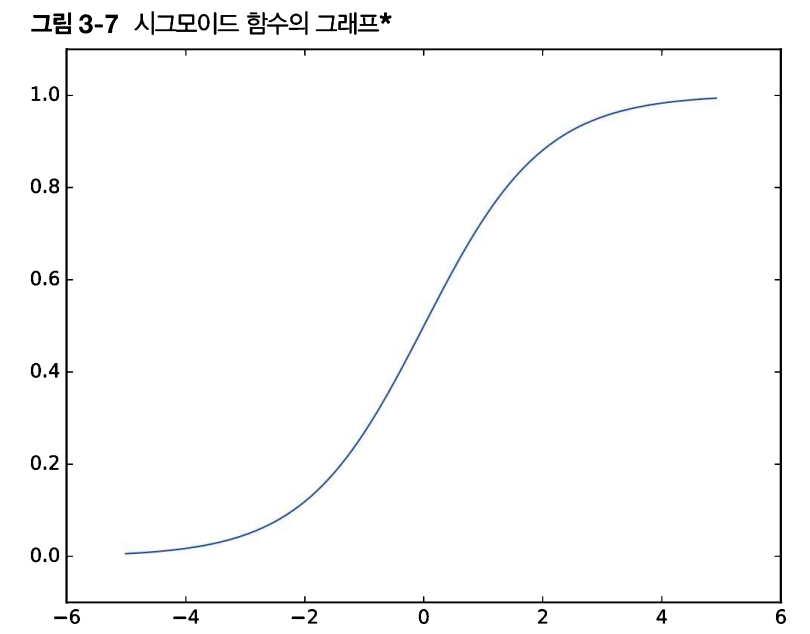
입력을 0~1 사이의 연속값으로 바꾸는 함수. 계단 함수와 달리 출력이 부드럽게 변해서 "얼마나 확실한지"를 표현할 수 있고 미분도 가능함. 주로 이진 분류의 출력층에서 확률을 내는 용도로 씀.


**ReLU**
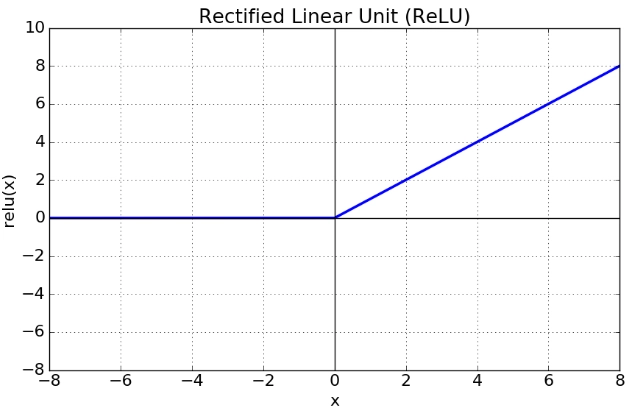
0보다 크면 그대로, 0 이하면 0을 출력하는 함수로, 현재 가장 많이 쓰임. 
왜?
 비교 연산 하나라 계산이 빠르고, 은닉층에 비선형성을 주며, 무엇보다 **양수 구간의 미분값이 항상 1**이라 아무리 곱해도 기울기가 줄어들지 않음.

**Softmax**
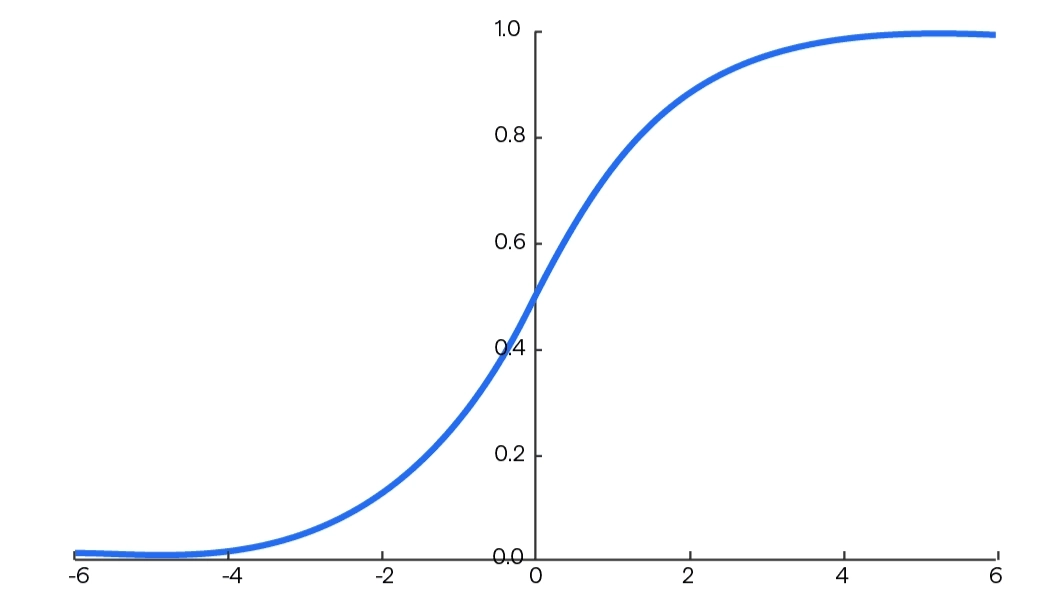
여러 클래스의 출력값을 합이 1인 확률로 바꿔 주는 함수로, 다중 분류의 출력층에서 사용함. 예를 들어 고양이·강아지·새를 구분할 때 [0.7, 0.2, 0.1]처럼 각 클래스일 확률을 바로 읽을 수 있다. CEE와 함께 쓰면 예측 확률과 정답의 차이를 바로 계산할 수 있어서, Softmax + CEE가 다중 분류의 표준 조합. 다만 출력층 전용이라 은닉층에는 맞지 않음.

**Tanh**
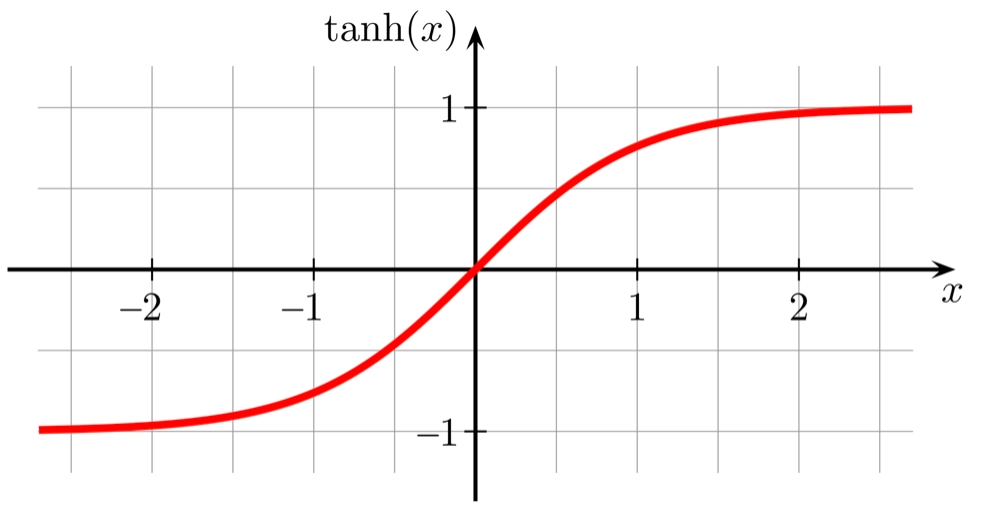
시그모이드를 변형해 출력 범위를 -1~1로 만든 함수. 출력 중심이 0이라 학습이 좀 더 안정적이지만, 입력이 크거나 작으면 역시 기울기 소실이 생겨서 요즘은 ReLU에 밀려 잘 쓰지 않음.

---가중치를 이제 어떻게 고쳐 나갈까?

### 2-4. 경사하강법

> **핵심** 기울기의 반대 방향으로 학습률만큼씩 이동해 손실의 최저점을 찾음. 실무에서는 미니 배치 방식을 씀

**원리**
경사하강법의 목표는 손실을 가장 작게 만드는 가중치 W를 찾는 것임. 즉 그냥 극값(미분값의 부호가 바뀌는지점)을 찾기
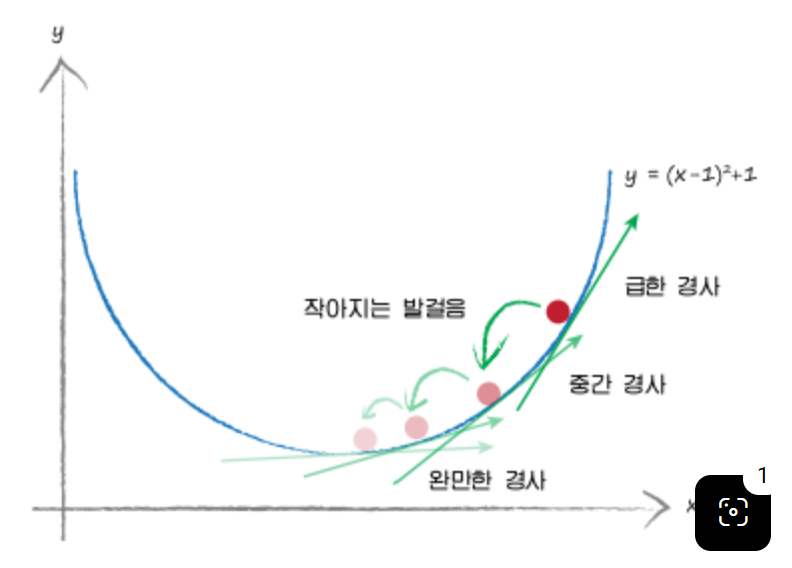

$$
W \leftarrow W - \alpha \frac{\partial E}{\partial W}
$$

안개 낀 산에서 발밑의 경사만 느끼면서, 가장 가파르게 내려가는 쪽으로 한 걸음씩 옮겨 골짜기를 찾는 상황으로 비유할 수 있음.

**학습률 (α)**
방향 알겟음 그럼 한 번에 얼마나 움직일지, 즉 보폭을 정해야 함. 미분값을 그대로 빼면 너무 크게 움직여 최저점을 계속 지나칠 수 있어서 α를 곱해 조절함. 학습률이 너무 작으면 수렴은 하지만 오래 걸리고, 너무 크면 수렴하지 못하고 손실이 오히려 커지는 발산이 일어남. 0.001부터 시작하면 됨
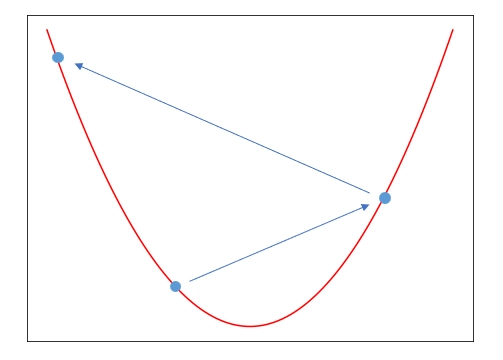

**배치 · 에포크 · 이터레이션**
기울기를 구하려면 데이터를 넣어야 하는데, 데이터가 많으면 한 번에 넣을 수 없어서 나눠서 넣음.
- **배치**: 한 번에 넣는 데이터 묶음. 너무 크면 느리고 메모리가 부족하며, 너무 작으면 업데이트가 잦아 불안정해짐
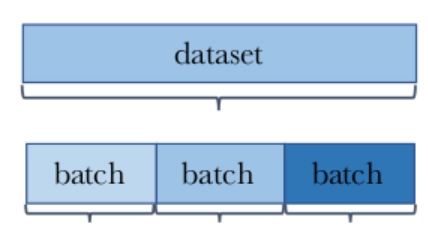
- **에포크**: 전체 데이터를 몇 번 반복해서 학습하는지 
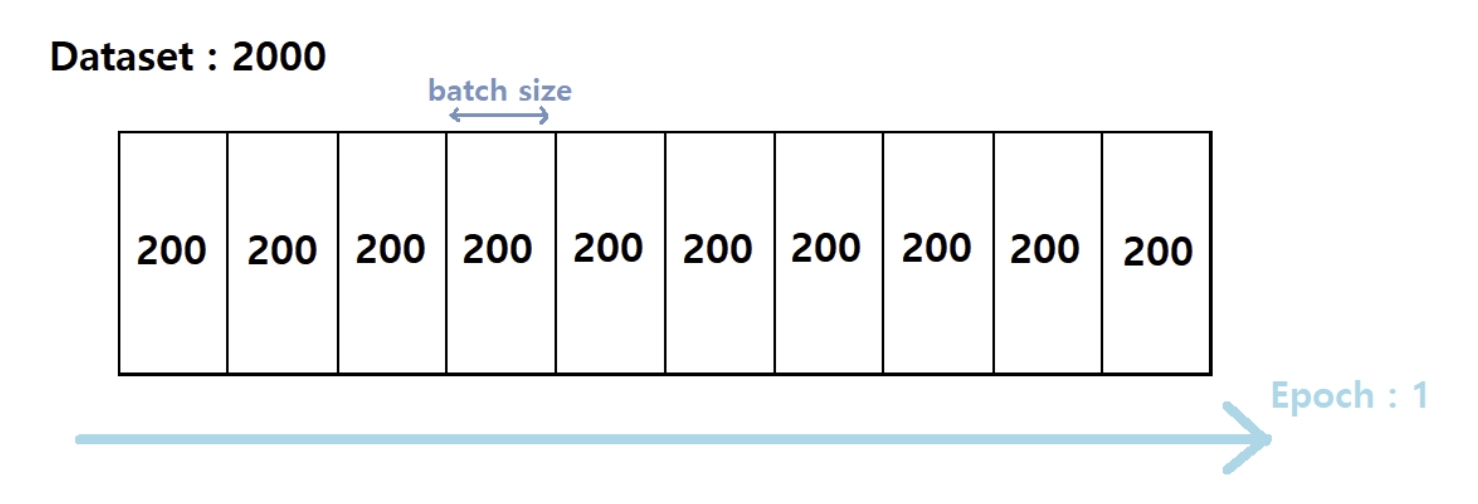
- **이터레이션**: 한 에포크를 끝내는 데 필요한 배치 수. 데이터 2,000개를 200개씩 나누면 10번

**경사하강법의 종류**
배치 크기에 따라 세 가지로 나뉨.
- **배치 경사하강법**은 전체 데이터를 한 번에 사용함. 에포크당 업데이트가 한 번뿐이고 메모리를 많이 쓰지만, 수렴이 안정적임
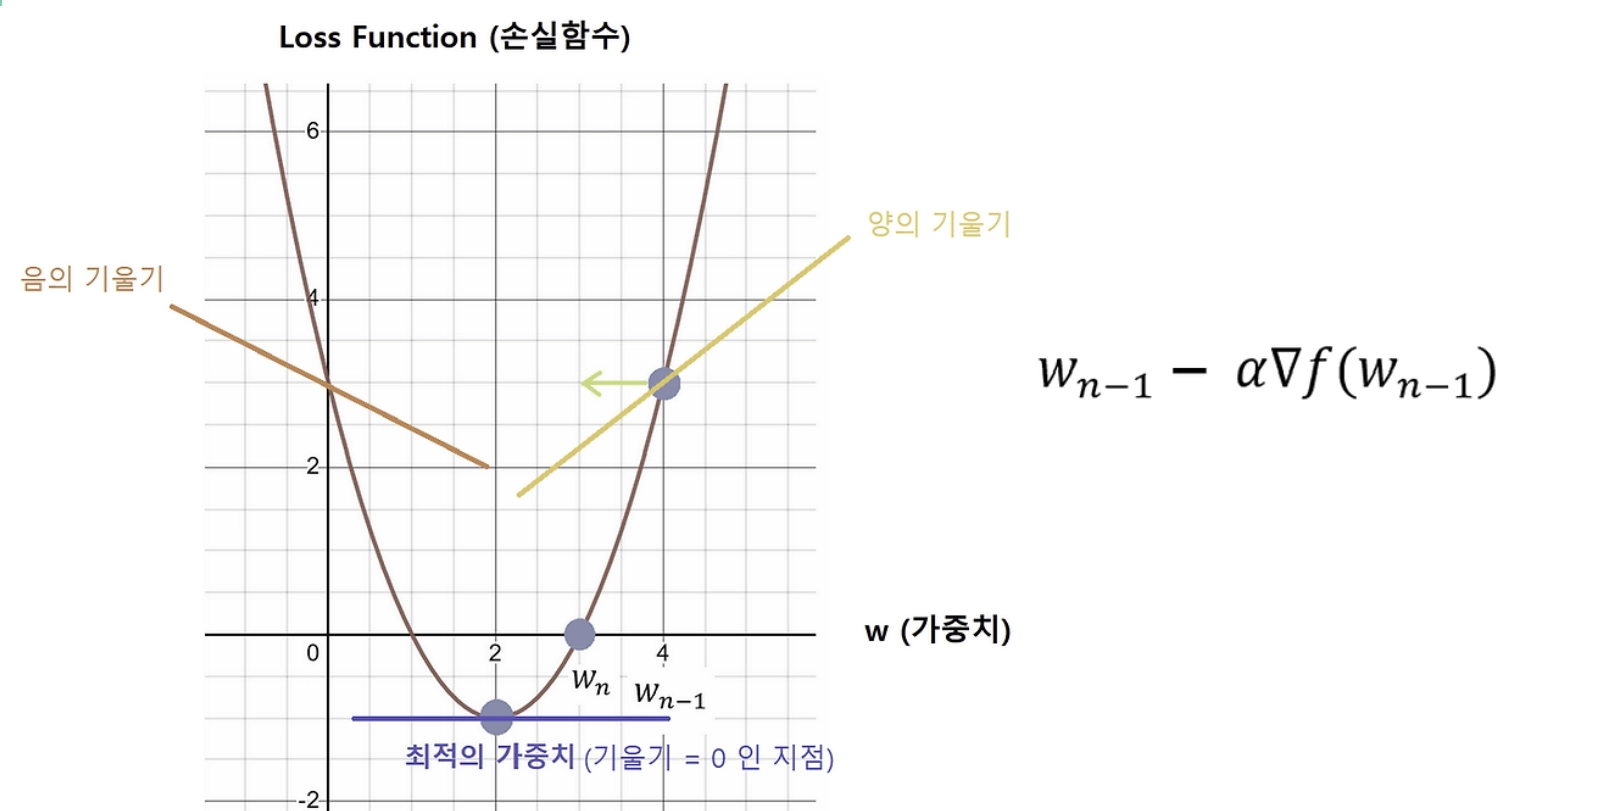
- **확률적 경사하강법(SGD)** 은 무작위로 고른 데이터 하나만 사용함. 메모리가 적게 들어 가볍지만, 업데이트 폭이 불안정하고 정확도가 떨어질 수 있음
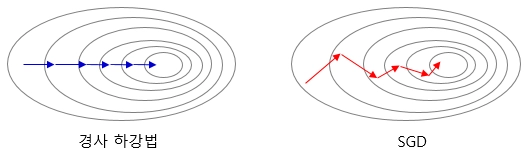
- **미니 배치 경사하강법**은 그 중간으로, 적당한 크기로 나눠 업데이트함. 전체 배치보다 빠르고 SGD보다 안정적이라 가장 많이 쓰임. Keras의 `batch_size` 기본값도 32이고, 보통 2의 거듭제곱으로 정함
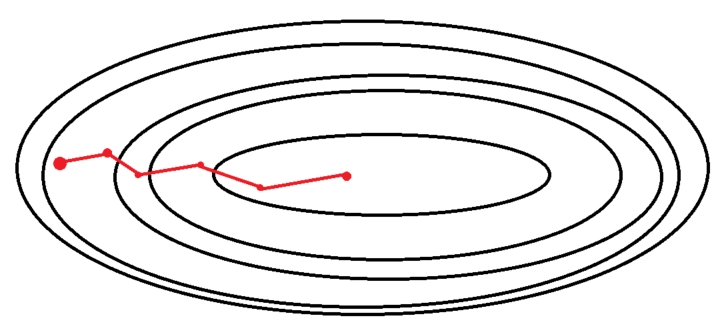

---

### 2-5. 옵티마이저

> **핵심** 울퉁불퉁한 손실 함수에서 경사하강법이 갇히지 않도록 보완하는 방법. 대부분의 경우 Adam으로 시작하면 됨

**경사하강법의 한계: Local Minima**
MSE처럼 볼록한 손실 함수라면 경사하강법만으로도 반드시 최저점에 도달함. 그러나 딥러닝은 층이 많아 손실 함수가 울퉁불퉁하고 모양을 예측할 수도 없음. 경사하강법은 기울기가 0이면 멈추는데, 진짜 최저점이 아닌 작은 웅덩이(Local Minimum)에서도 기울기가 0이라 그곳에 갇힐 수 있음. 기울기가 완만한 구간에서도 조금씩만 움직여서 빠져나오는 데 오래 걸림. 이를 해결하기 위한 방법이 옵티마이저이고, 그중 핵심이 모멘텀, RMSProp, Adam임.

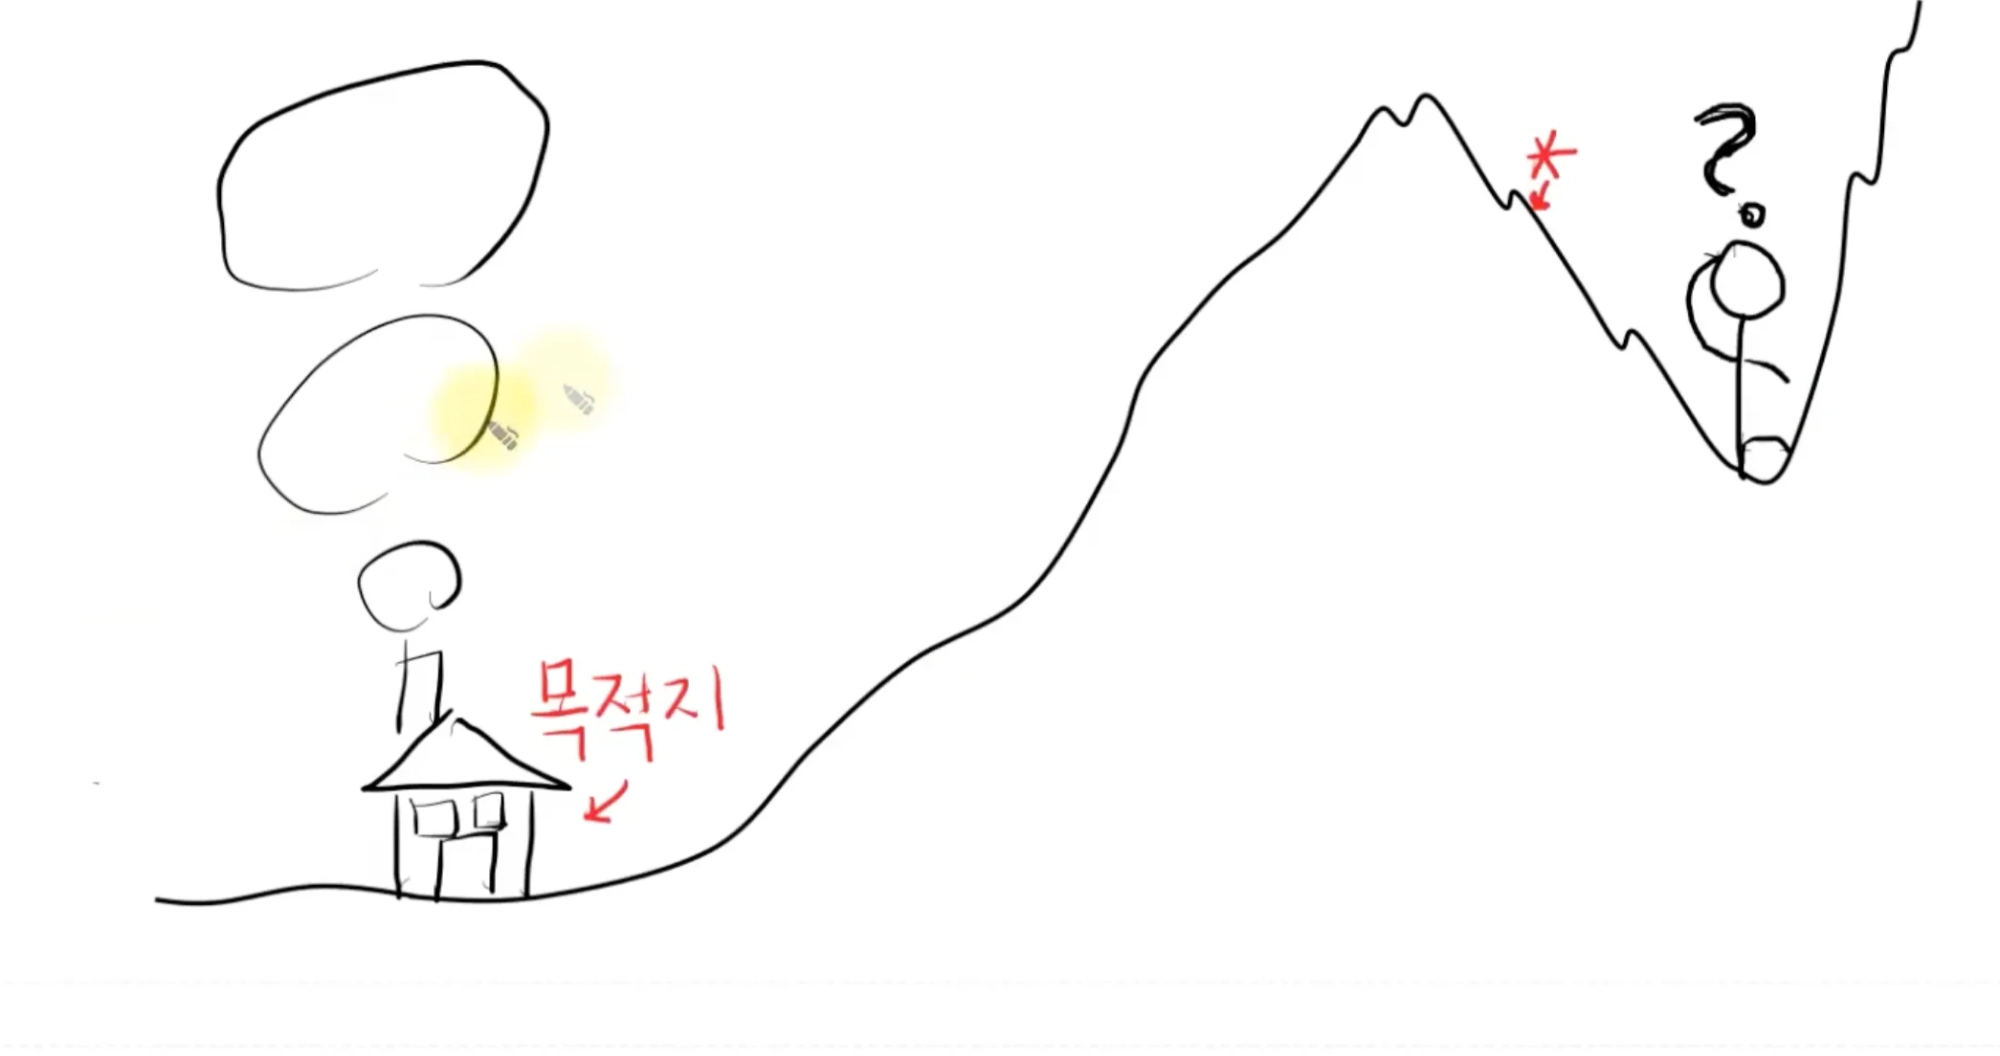

**모멘텀**
 이전에 가던 방향을 기억하도록 관성을 부여! 

**RMSProp**
기존 경사하강법은 기울기가 큰 방향으로는 너무 많이, 작은 방향으로는 너무 조금 움직이는 문제가 있음. RMSProp은 최근 기울기를 참고해 **방향마다 학습률을 따로 조절**함. 즉 !  가파른 곳에서는 속도를 줄이고, 완만한 곳에서는 속도를 유지하거나 높여서 안정적으로 내려감.

**Adam**
모멘텀 + RMSProp 방법으로, 기울기의 평균(1차 모멘트)과 기울기 제곱의 평균(2차 모멘트)을 함께 써서 **방향과 보폭을 모두** 조절

**선택 기준**
일단 adam으로 시작!
| 이럴 때 | 이걸 쓰세요 | 왜 |
| --- | --- | --- |
| 잘 모르겠다 / 대부분의 경우 | Adam | 방향과 보폭을 둘 다 잡음. 사실상 기본값 |
| 학습이 자꾸 한쪽으로 튄다 | 모멘텀 | 방향을 안정화 |
| 파라미터마다 기울기 크기 차이가 크다 | RMSProp | 방향별로 학습률을 따로 조정 |

모멘텀 = 방향을 개선
RMSProp = 보폭(학습률)을 개선
Adam = 둘 다 = 모멘텀 + RMSProp

---

### 2-6. 코드로 보는 전체 내용 정리

> **핵심** 모델을 짤 때 정해야 하는 것은 activation, loss, optimizer, batch_size 

지금까지 배운 내용은 모델 구조, 학습 방법 설정, 학습 실행의 세 단계 코드에 모두 담겨 있음.

```python
# 모델 구조
model = Sequential()
model.add(Dense(10, input_dim=5, activation='relu'))
model.add(Dense(3, activation='softmax'))

# 학습 방법 설정
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['acc'])

# 학습 실행
model.fit(X_train, y_train, batch_size=32, epochs=10)
```

코드를 한 줄씩 해석하면 다음과 같음.
- `Dense(10, input_dim=5, activation='relu')` → 특성 5개를 받아 뉴런 10개짜리 은닉층을 만들고, 기울기 소실을 막기 위해 ReLU를 적용함 (1-3, 2-3)
- `Dense(3, activation='softmax')` → 출력 노드 3개에 Softmax를 적용해 각 클래스일 확률을 출력함 (2-3)
- `loss='categorical_crossentropy'` → 다중 분류이므로 CEE를 사용함 (2-2)
- `optimizer='adam'` → 모멘텀과 RMSProp을 합친 Adam으로 가중치를 업데이트함 (2-5)
- `batch_size=32, epochs=10` → 32개씩 미니 배치로 나눠 전체 데이터를 10번 학습함 (2-4)

출력이 3개이고 Softmax와 categorical_crossentropy를 썼다는 점에서 이 모델이 **3개 클래스 중 하나를 고르는 다중 분류 모델**이라는 걸 코드만 보고도 알 수 있다

**잘못된 설정 예시**
출력 노드가 1개인데 `activation='softmax'`를 쓰면, Softmax는 전체 합을 1로 만드는 함수라 결과가 무조건 1이 나와서 학습이 전혀 x . 이진 분류가 목적이었다면 `sigmoid` + `binary_crossentropy`를, 회귀가 목적이었다면 활성화 함수 없이 `mse`를 써야 함.

